In [1]:

# ============================================
# CELL 1: INSTALL PROJECT DEPENDENCIES
# ============================================

%pip install -q pymoo xgboost imbalanced-learn shap gradio openpyxl

print("All project libraries installed successfully!")


All project libraries installed successfully!


In [2]:

# ============================================
# CELL 2: IMPORT LIBRARIES
# ============================================

import os
import time
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    chi2,
    RFE
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

np.random.seed(SEED)
random.seed(SEED)

# Display settings
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Imports completed successfully!")
print("Random seed:", SEED)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Imports completed successfully!
Random seed: 42
Pandas version: 2.2.3
NumPy version: 2.4.6


In [3]:

# ============================================
# CELL 3: UPLOAD DATASET
# ============================================

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

print("Uploaded file:", file_name)

# Read Excel dataset
df = pd.read_excel(file_name)

print("Dataset loaded successfully!")


Saving Telco_customer_churn.xlsx to Telco_customer_churn.xlsx
Uploaded file: Telco_customer_churn.xlsx
Dataset loaded successfully!


In [4]:

# ============================================
# CELL 4: DATASET INSPECTION
# ============================================

print("=" * 55)
print("TELCO CUSTOMER CHURN DATASET")
print("=" * 55)

# Dataset dimensions
print("\nDataset Shape:", df.shape)

# First five records
print("\nFirst Five Records:")
display(df.head())

# Column information
print("\nColumn Names:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Target distribution
print("\nChurn Distribution:")
display(df["Churn Label"].value_counts())

# Target percentages
print("\nChurn Percentage:")
display(
    df["Churn Label"].value_counts(normalize=True) * 100
)


TELCO CUSTOMER CHURN DATASET

Dataset Shape: (7043, 33)

First Five Records:


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices



Column Names:
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']

Data Types:
CustomerID            object
Count                  int64
Country               object
State                 object
City                  object
Zip Code               int64
Lat Long              object
Latitude             float64
Longitude            float64
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service 

,count
Churn Label,
No,5174
Yes,1869



Churn Percentage:


,proportion
Churn Label,
No,73.463013
Yes,26.536987


In [8]:
# Convert Total Charges safely
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"], errors="coerce"
)

print("Missing Total Charges before filling:",
      df["Total Charges"].isna().sum())

# Fill blank charges for customers with zero tenure
mask = df["Total Charges"].isna() & (df["Tenure Months"] == 0)
df.loc[mask, "Total Charges"] = 0.0

print("Filled zero-tenure records:", mask.sum())
print("Missing Total Charges after filling:",
      df["Total Charges"].isna().sum())

print("Total Charges datatype:", df["Total Charges"].dtype)

print("\nDuplicate records:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["Churn Label"].value_counts())

print("\nCell 5 completed!")

Missing Total Charges before filling: 11
Filled zero-tenure records: 11
Missing Total Charges after filling: 0
Total Charges datatype: float64

Duplicate records: 0

Target distribution:
Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

Cell 5 completed!


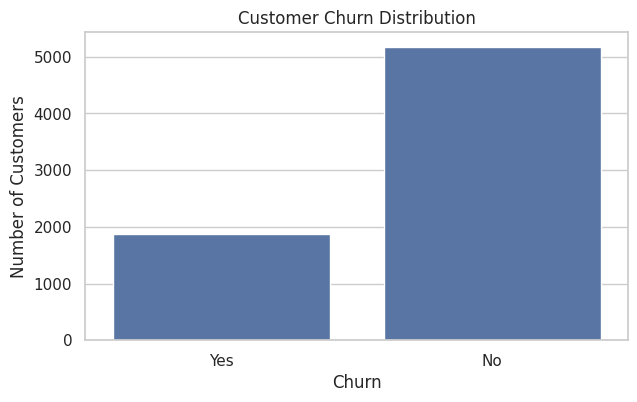

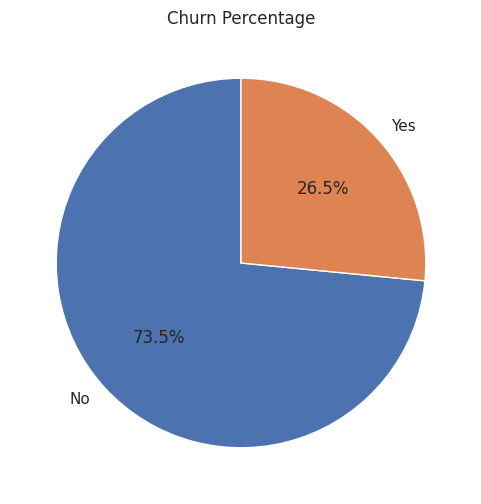

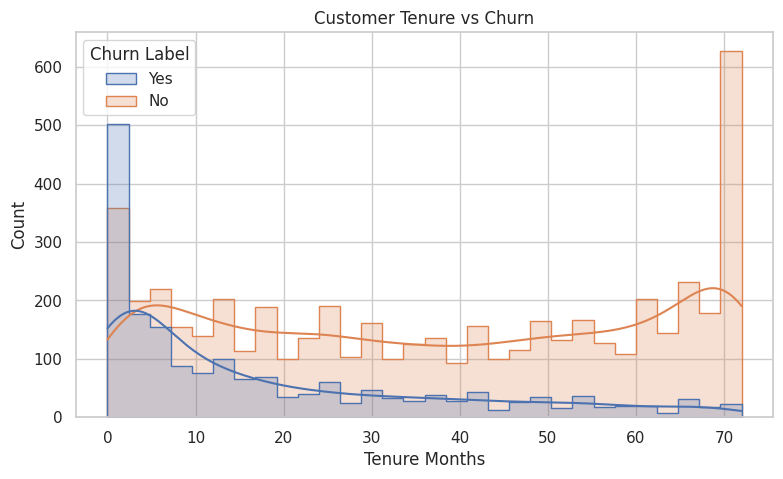

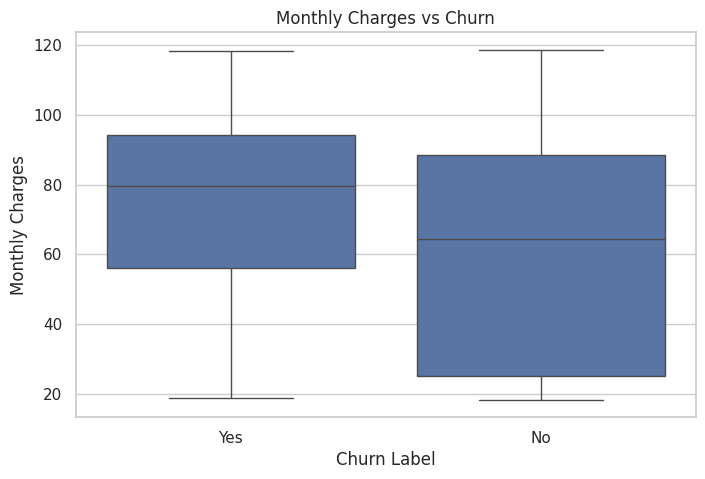

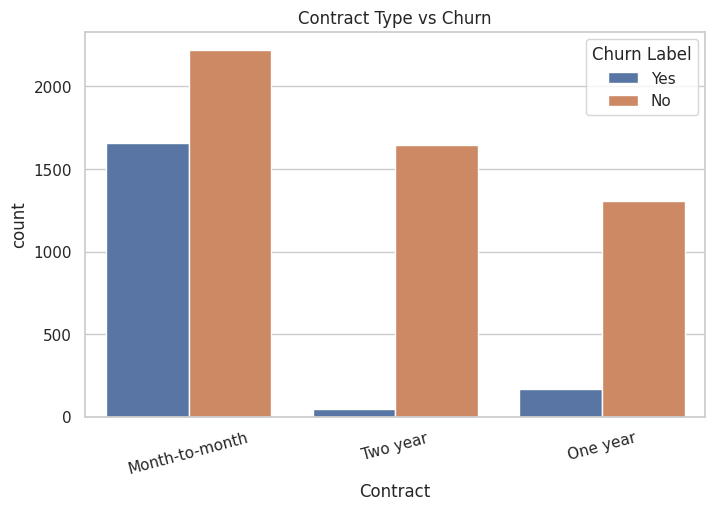

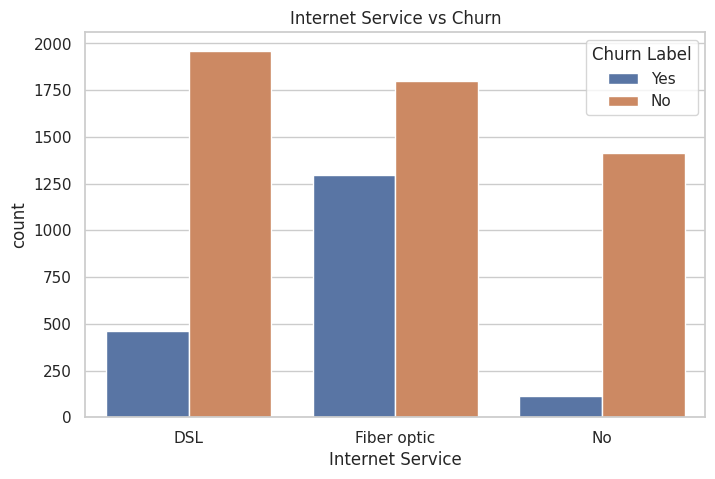

EDA completed successfully!


In [9]:
# ==========================================
# CELL 6: EXPLORATORY DATA ANALYSIS
# ==========================================

# 1. Churn distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Churn Label")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

# 2. Churn percentage
churn_percent = df["Churn Label"].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 6))
plt.pie(
    churn_percent,
    labels=churn_percent.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Churn Percentage")
plt.show()

# 3. Tenure distribution by churn
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="Tenure Months",
    hue="Churn Label",
    bins=30,
    kde=True,
    element="step"
)
plt.title("Customer Tenure vs Churn")
plt.show()

# 4. Monthly charges by churn
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn Label", y="Monthly Charges")
plt.title("Monthly Charges vs Churn")
plt.show()

# 5. Contract type vs churn
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Contract", hue="Churn Label")
plt.title("Contract Type vs Churn")
plt.xticks(rotation=15)
plt.show()

# 6. Internet service vs churn
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Internet Service", hue="Churn Label")
plt.title("Internet Service vs Churn")
plt.show()

print("EDA completed successfully!")

In [11]:
# ==========================================
# CELL 7: CHURN RATE ANALYSIS
# ==========================================

categorical_features = [
    "Contract",
    "Internet Service",
    "Payment Method",
    "Online Security",
    "Tech Support",
    "Paperless Billing",
    "Senior Citizen"
]

for col in categorical_features:
    print(f"\n{'='*45}")
    print(f"Churn Rate by {col}")
    print("="*45)

    churn_rate = (
        df.groupby(col, observed=False)["Churn Label"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    display(churn_rate.round(2).rename("Churn Rate (%)").to_frame())

print("\nCell 7 completed!")


Churn Rate by Contract


,Churn Rate (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83



Churn Rate by Internet Service


,Churn Rate (%)
Internet Service,
Fiber optic,41.89
DSL,18.96
No,7.40



Churn Rate by Payment Method


,Churn Rate (%)
Payment Method,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24


... (5 outputs left out)

,Churn Rate (%)
Paperless Billing,
Yes,33.57
No,16.33



Churn Rate by Senior Citizen


,Churn Rate (%)
Senior Citizen,
Yes,41.68
No,23.61



Cell 7 completed!


In [12]:
# ==========================================
# CELL 8: FEATURE PREPARATION
# ==========================================

# Target variable
target = "Churn Label"

# Columns to exclude
exclude_columns = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
    "Churn Value",
    "Churn Score",
    "Churn Reason"
]

# Create feature matrix and target
X = df.drop(columns=exclude_columns + [target])
y = df[target].map({"No": 0, "Yes": 1})

# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Original dataset shape:", df.shape)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

print("\nTarget distribution:")
print(y.value_counts())

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nCell 8 completed!")

Original dataset shape: (7043, 33)
Feature matrix shape: (7043, 20)
Target shape: (7043,)

Numerical features: 4
['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']

Categorical features: 16
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']

Target distribution:
Churn Label
0    5174
1    1869
Name: count, dtype: int64

Training samples: 5634
Testing samples: 1409

Cell 8 completed!


In [13]:
# ==========================================
# CELL 9: DATA PREPROCESSING
# ==========================================

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
# Supports both newer and older scikit-learn versions
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without fitting again
X_test_processed = preprocessor.transform(X_test)

# Get transformed feature names
encoded_feature_names = preprocessor.get_feature_names_out()

print("Preprocessing completed successfully!")

print("\nOriginal training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nNumber of encoded columns:", len(encoded_feature_names))

print("\nSample encoded feature names:")
print(encoded_feature_names[:20])

print("\nMissing values in processed training data:",
      np.isnan(X_train_processed.data).sum()
      if hasattr(X_train_processed, "data")
      else np.isnan(X_train_processed).sum())

print("\nCell 9 completed!")

Preprocessing completed successfully!

Original training shape: (5634, 20)
Processed training shape: (5634, 47)

Original testing shape: (1409, 20)
Processed testing shape: (1409, 47)

Number of encoded columns: 47

Sample encoded feature names:
['num__Tenure Months' 'num__Monthly Charges' 'num__Total Charges'
 'num__CLTV' 'cat__Gender_Female' 'cat__Gender_Male'
 'cat__Senior Citizen_No' 'cat__Senior Citizen_Yes' 'cat__Partner_No'
 'cat__Partner_Yes' 'cat__Dependents_No' 'cat__Dependents_Yes'
 'cat__Phone Service_No' 'cat__Phone Service_Yes' 'cat__Multiple Lines_No'
 'cat__Multiple Lines_No phone service' 'cat__Multiple Lines_Yes'
 'cat__Internet Service_DSL' 'cat__Internet Service_Fiber optic'
 'cat__Internet Service_No']

Missing values in processed training data: 0

Cell 9 completed!


In [14]:
# ==========================================
# CELL 10: BASELINE MODEL EVALUATION
# ==========================================

from sklearn.base import clone

baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    )
}

baseline_results = []
trained_baseline_models = {}

for model_name, model in baseline_models.items():

    print(f"\nTraining {model_name}...")

    start_time = time.time()

    model.fit(X_train_processed, y_train)

    training_time = time.time() - start_time

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob),
        "Training Time (seconds)": training_time
    }

    baseline_results.append(results)
    trained_baseline_models[model_name] = model

    print(f"{model_name} completed!")

# Display comparison
baseline_df = pd.DataFrame(baseline_results)

print("\nBASELINE MODEL COMPARISON")
display(baseline_df.round(4))

print("\nClassification Reports")

for model_name, model in trained_baseline_models.items():

    print(f"\n{'='*50}")
    print(model_name)
    print("="*50)

    y_pred = model.predict(X_test_processed)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"]
    ))

print("\nCell 10 completed!")


Training Logistic Regression...
Logistic Regression completed!

Training Random Forest...
Random Forest completed!

BASELINE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Training Time (seconds)
0,Logistic Regression,0.7431,0.5105,0.7834,0.6181,0.8489,0.6449,0.2272
1,Random Forest,0.7899,0.6327,0.4973,0.5569,0.8371,0.6294,2.7181



Classification Reports

Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409


Random Forest
              precision    recall  f1-score   support

    No Churn       0.83      0.90      0.86      1035
       Churn       0.63      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409


Cell 10 completed!


In [15]:
# ==========================================
# CELL 11: REUSABLE FEATURE EVALUATION ENGINE
# ==========================================

from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

def build_evaluation_pipeline(selected_features):

    selected_numeric = [
        col for col in selected_features
        if col in numeric_features
    ]

    selected_categorical = [
        col for col in selected_features
        if col in categorical_features
    ]

    transformers = []

    if selected_numeric:
        numeric_pipeline = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])

        transformers.append(
            ("num", numeric_pipeline, selected_numeric)
        )

    if selected_categorical:
        try:
            encoder = OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        except TypeError:
            encoder = OneHotEncoder(
                handle_unknown="ignore",
                sparse=True
            )

        categorical_pipeline = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", encoder)
        ])

        transformers.append(
            ("cat", categorical_pipeline, selected_categorical)
        )

    subset_preprocessor = ColumnTransformer(
        transformers=transformers
    )

    pipeline = Pipeline(steps=[
        ("preprocessor", subset_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=SEED
        ))
    ])

    return pipeline


# Evaluate all 20 features using training-only cross-validation
all_features = X_train.columns.tolist()

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

scoring = {
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

baseline_cv_pipeline = build_evaluation_pipeline(all_features)

cv_results = cross_validate(
    baseline_cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

print("=" * 55)
print("TRAINING DATA: 5-FOLD CROSS-VALIDATION")
print("=" * 55)

for metric in scoring:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():12s}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

print("\nAverage CV training time:",
      round(cv_results["fit_time"].mean(), 4), "seconds")

print("\nNumber of original features:", len(all_features))
print("Cell 11 completed!")

TRAINING DATA: 5-FOLD CROSS-VALIDATION
F1          : 0.6401 +/- 0.0214
RECALL      : 0.8094 +/- 0.0332
PRECISION   : 0.5297 +/- 0.0203
ROC_AUC     : 0.8588 +/- 0.0125
PR_AUC      : 0.6789 +/- 0.0206

Average CV training time: 0.3894 seconds

Number of original features: 20
Cell 11 completed!


In [16]:
# ==========================================
# CELL 12: EVOLUTIONARY FITNESS ENGINE
# ==========================================

from functools import lru_cache

# Three-fold CV makes repeated evolutionary evaluations practical
evolution_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

fitness_cache = {}

def evaluate_chromosome(chromosome):

    # Convert chromosome into a stable cache key
    chromosome = np.asarray(chromosome, dtype=int)
    cache_key = tuple(chromosome.tolist())

    if cache_key in fitness_cache:
        return fitness_cache[cache_key]

    # Identify selected original features
    selected_features = [
        all_features[i]
        for i, bit in enumerate(chromosome)
        if bit == 1
    ]

    # Reject empty feature subsets
    if len(selected_features) == 0:
        result = {
            "f1": 0.0,
            "recall": 0.0,
            "precision": 0.0,
            "roc_auc": 0.0,
            "pr_auc": 0.0,
            "feature_count": 0
        }
        fitness_cache[cache_key] = result
        return result

    # Build preprocessing + Logistic Regression pipeline
    pipeline = build_evaluation_pipeline(selected_features)

    # Evaluate using training data only
    scores = cross_validate(
        pipeline,
        X_train[selected_features],
        y_train,
        cv=evolution_cv,
        scoring={
            "f1": "f1",
            "recall": "recall",
            "precision": "precision",
            "roc_auc": "roc_auc",
            "pr_auc": "average_precision"
        },
        n_jobs=1,
        return_train_score=False
    )

    result = {
        "f1": float(np.mean(scores["test_f1"])),
        "recall": float(np.mean(scores["test_recall"])),
        "precision": float(np.mean(scores["test_precision"])),
        "roc_auc": float(np.mean(scores["test_roc_auc"])),
        "pr_auc": float(np.mean(scores["test_pr_auc"])),
        "feature_count": len(selected_features)
    }

    fitness_cache[cache_key] = result

    return result


# Test the evaluation engine with all 20 features
all_features_chromosome = np.ones(len(all_features), dtype=int)

test_fitness = evaluate_chromosome(all_features_chromosome)

print("=" * 55)
print("EVOLUTIONARY FITNESS ENGINE TEST")
print("=" * 55)

print("\nSelected features:", test_fitness["feature_count"])

for metric, value in test_fitness.items():
    if metric != "feature_count":
        print(f"{metric.upper():12s}: {value:.4f}")

print("\nCached evaluations:", len(fitness_cache))
print("Cell 12 completed!")

EVOLUTIONARY FITNESS ENGINE TEST

Selected features: 20
F1          : 0.6425
RECALL      : 0.8127
PRECISION   : 0.5314
ROC_AUC     : 0.8586
PR_AUC      : 0.6764

Cached evaluations: 1
Cell 12 completed!


In [17]:
# ==========================================
# CELL 13: NSGA-II PROBLEM DEFINITION
# ==========================================

from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.operators.sampling.rnd import BinaryRandomSampling
from pymoo.operators.crossover.ux import UniformCrossover
from pymoo.operators.mutation.bitflip import BitflipMutation
from pymoo.termination import get_termination
from pymoo.optimize import minimize

class FeatureSelectionProblem(ElementwiseProblem):

    def __init__(self):
        super().__init__(
            n_var=len(all_features),
            n_obj=3,
            n_ieq_constr=0,
            xl=0,
            xu=1,
            vtype=bool
        )

    def _evaluate(self, x, out, *args, **kwargs):

        result = evaluate_chromosome(x)

        # NSGA-II minimizes all objectives
        out["F"] = [
            1.0 - result["f1"],
            1.0 - result["recall"],
            result["feature_count"]
        ]


# Create the optimization problem
problem = FeatureSelectionProblem()

# Configure NSGA-II
algorithm = NSGA2(
    pop_size=30,
    sampling=BinaryRandomSampling(),
    crossover=UniformCrossover(prob=0.85),
    mutation=BitflipMutation(prob=0.05),
    eliminate_duplicates=True
)

# Termination condition
termination = get_termination("n_gen", 30)

print("NSGA-II problem created successfully!")
print("Number of decision variables:", problem.n_var)
print("Number of objectives:", problem.n_obj)
print("Population size:", algorithm.pop_size)
print("Generations:", 30)
print("Crossover probability:", 0.85)
print("Mutation probability:", 0.05)

print("\nCell 13 completed!")

NSGA-II problem created successfully!
Number of decision variables: 20
Number of objectives: 3
Population size: 30
Generations: 30
Crossover probability: 0.85
Mutation probability: 0.05

Cell 13 completed!


In [18]:
# ==========================================
# CELL 14: EXECUTE NSGA-II
# ==========================================

print("=" * 60)
print("STARTING NSGA-II FEATURE SELECTION")
print("=" * 60)

start_time = time.time()

res = minimize(
    problem,
    algorithm,
    termination,
    seed=SEED,
    save_history=True,
    verbose=True
)

optimization_time = time.time() - start_time

print("\n" + "=" * 60)
print("NSGA-II OPTIMIZATION COMPLETED")
print("=" * 60)

print("Total optimization time:",
      round(optimization_time, 2), "seconds")

print("Generations completed:", len(res.history))
print("Pareto solutions found:",
      0 if res.F is None else len(res.F))

print("Unique feature subsets evaluated:",
      len(fitness_cache))

print("\nCell 14 completed!")

STARTING NSGA-II FEATURE SELECTION
n_gen  |  n_eval  | n_nds  |      eps      |   indicator  
     1 |       30 |      8 |             - |             -
     2 |       60 |     16 |  0.1214803115 |         ideal
     3 |       90 |     20 |  0.4524419548 |         ideal
     4 |      120 |     24 |  0.0346564022 |             f
     5 |      150 |     19 |  0.0833333333 |         ideal
     6 |      180 |     23 |  0.2534986514 |         ideal
     7 |      210 |     28 |  0.0213116109 |             f
     8 |      240 |     16 |  0.0262516132 |             f
     9 |      270 |     25 |  0.0714285714 |         ideal
    10 |      300 |     26 |  0.0223759529 |             f
    11 |      330 |     28 |  0.0131375658 |             f
    12 |      360 |     28 |  0.0087708813 |             f
    13 |      390 |     28 |  0.0169555432 |             f
    14 |      420 |     30 |  0.0060483381 |             f
    15 |      450 |     30 |  0.0036158503 |             f
    16 |      480 |  

In [19]:
# ==========================================
# CELL 15: PARETO SOLUTION EXTRACTION
# ==========================================

pareto_results = []

for i, chromosome in enumerate(res.X):

    chromosome = np.asarray(chromosome, dtype=int)

    result = evaluate_chromosome(chromosome)

    selected_features = [
        all_features[j]
        for j, bit in enumerate(chromosome)
        if bit == 1
    ]

    pareto_results.append({
        "Solution": i + 1,
        "F1 Score": result["f1"],
        "Recall": result["recall"],
        "Precision": result["precision"],
        "ROC-AUC": result["roc_auc"],
        "PR-AUC": result["pr_auc"],
        "Feature Count": result["feature_count"],
        "Selected Features": ", ".join(selected_features)
    })

pareto_df = pd.DataFrame(pareto_results)

# Sort by F1-score for easier inspection
pareto_df = pareto_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("=" * 70)
print("PARETO-OPTIMAL FEATURE SELECTION RESULTS")
print("=" * 70)

display(pareto_df.round(4))

print("\nTotal Pareto solutions:", len(pareto_df))

print("\nFeature count range:")
print(
    pareto_df["Feature Count"].min(),
    "to",
    pareto_df["Feature Count"].max()
)

print("\nCell 15 completed!")

PARETO-OPTIMAL FEATURE SELECTION RESULTS


,Solution,F1 Score,Recall,Precision,ROC-AUC,PR-AUC,Feature Count,Selected Features
0,1,0.6480,0.8201,0.5357,0.8577,0.6762,14,"Dependents, Tenure Months, Phone Service, Inte..."
1,11,0.6463,0.8214,0.5328,0.8580,0.6748,12,"Dependents, Tenure Months, Phone Service, Inte..."
2,18,0.6450,0.8074,0.5372,0.8567,0.6693,10,"Dependents, Tenure Months, Phone Service, Inte..."
3,21,0.6448,0.8221,0.5305,0.8569,0.6707,12,"Senior Citizen, Dependents, Tenure Months, Pho..."
4,9,0.6445,0.8094,0.5357,0.8564,0.6726,11,"Senior Citizen, Dependents, Tenure Months, Pho..."
5,17,0.6429,0.8174,0.5299,0.8559,0.6699,10,"Dependents, Tenure Months, Phone Service, Inte..."
6,14,0.6423,0.8053,0.5342,0.8563,0.6677,9,"Dependents, Tenure Months, Phone Service, Onli..."
7,24,0.6414,0.8361,0.5204,0.8488,0.6444,8,"Senior Citizen, Dependents, Tenure Months, Pho..."
8,13,0.6407,0.8301,0.5219,0.8490,0.6466,7,"Senior Citizen, Dependents, Tenure Months, Tec..."
9,20,0.6371,0.8334,0.5158,0.8488,0.6453,7,"Dependents, Tenure Months, Phone Service, Tech..."



Total Pareto solutions: 30

Feature count range:
1 to 14

Cell 15 completed!


In [20]:
# ==========================================
# CELL 16: SELECT THE BALANCED PARETO SOLUTION
# ==========================================

# Solution 11 corresponds to index 10 in res.X
selected_solution_number = 11
selected_chromosome = np.asarray(
    res.X[selected_solution_number - 1], dtype=int
)

# Extract selected original features
selected_features = [
    all_features[i]
    for i, bit in enumerate(selected_chromosome)
    if bit == 1
]

# Evaluate selected subset using training-only CV
selected_result = evaluate_chromosome(selected_chromosome)

print("=" * 60)
print("SELECTED NSGA-II FEATURE SUBSET")
print("=" * 60)

print("Selected solution:", selected_solution_number)
print("Number of selected features:", len(selected_features))

print("\nSelected features:")
for i, feature in enumerate(selected_features, 1):
    print(f"{i}. {feature}")

print("\nTraining-only 3-fold CV performance:")
for metric, value in selected_result.items():
    print(f"{metric}: {value}")

SELECTED NSGA-II FEATURE SUBSET
Selected solution: 11
Number of selected features: 12

Selected features:
1. Dependents
2. Tenure Months
3. Phone Service
4. Internet Service
5. Online Security
6. Tech Support
7. Streaming TV
8. Contract
9. Paperless Billing
10. Payment Method
11. Total Charges
12. CLTV

Training-only 3-fold CV performance:
f1: 0.6462940568203727
recall: 0.8214018398242268
precision: 0.5328061122015024
roc_auc: 0.8579715429710933
pr_auc: 0.6747661176487809
feature_count: 12


In [21]:
# ==========================================
# CELL 17: FINAL TEST SET EVALUATION
# ==========================================

# Build a fresh pipeline using selected features
final_pipeline = build_evaluation_pipeline(selected_features)

# Train only on the training data
start_time = time.time()

final_pipeline.fit(
    X_train[selected_features],
    y_train
)

final_training_time = time.time() - start_time

# Predictions on untouched test data
y_pred = final_pipeline.predict(
    X_test[selected_features]
)

y_prob = final_pipeline.predict_proba(
    X_test[selected_features]
)[:, 1]

# Calculate test metrics
final_test_results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR-AUC": average_precision_score(y_test, y_prob),
    "Training Time (seconds)": final_training_time,
    "Selected Features": len(selected_features)
}

print("=" * 60)
print("NSGA-II FEATURE SELECTION - FINAL TEST RESULTS")
print("=" * 60)

for metric, value in final_test_results.items():
    print(f"{metric}: {value:.4f}" if isinstance(value, (float, np.floating))
          else f"{metric}: {value}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No Churn", "Churn"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

NSGA-II FEATURE SELECTION - FINAL TEST RESULTS
Accuracy: 0.7452
Precision: 0.5132
Recall: 0.7807
F1 Score: 0.6193
ROC-AUC: 0.8486
PR-AUC: 0.6531
Training Time (seconds): 0.0915
Selected Features: 12

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.75      0.76      1409


Confusion Matrix:
[[758 277]
 [ 82 292]]


,Metric,All 20 Features,NSGA-II (12 Features)
0,Accuracy,0.7431,0.7452
1,Precision,0.5105,0.5132
2,Recall,0.7834,0.7807
3,F1 Score,0.6181,0.6193
4,ROC-AUC,0.8489,0.8486
5,PR-AUC,0.6449,0.6531
6,Training Time (seconds),0.2272,0.0915


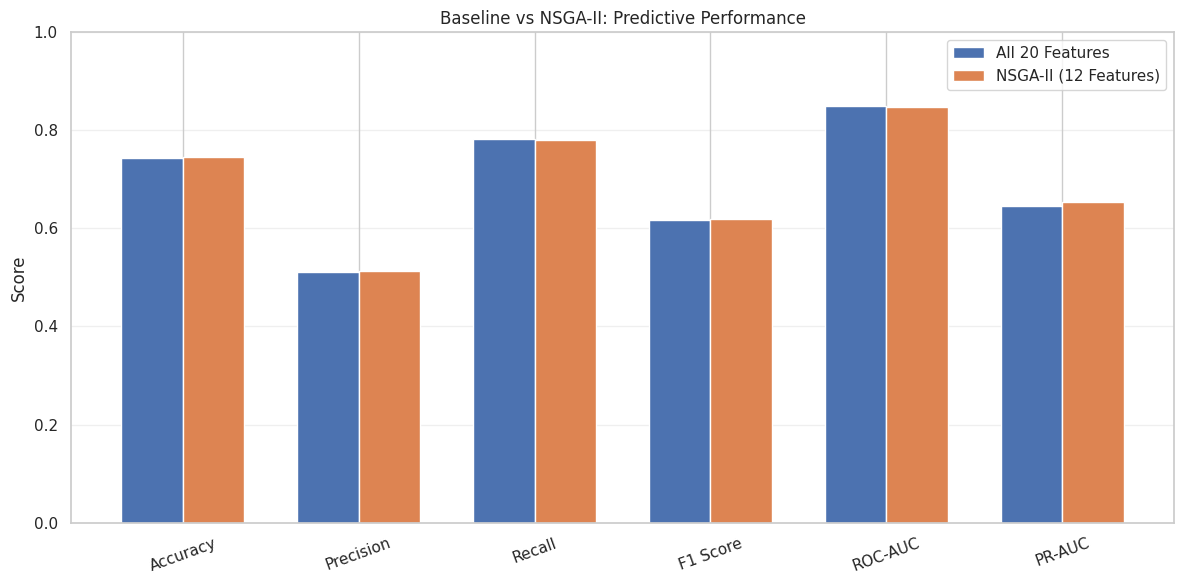

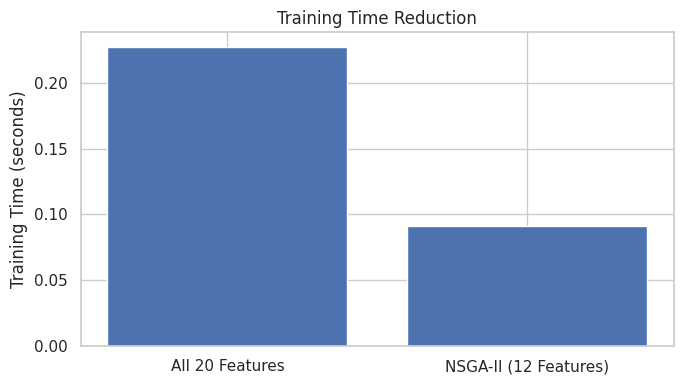

In [22]:
# ==========================================
# CELL 18: BASELINE VS NSGA-II COMPARISON
# ==========================================

comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision", "Recall",
        "F1 Score", "ROC-AUC", "PR-AUC",
        "Training Time (seconds)"
    ],
    "All 20 Features": [
        0.7431, 0.5105, 0.7834,
        0.6181, 0.8489, 0.6449, 0.2272
    ],
    "NSGA-II (12 Features)": [
        0.7452, 0.5132, 0.7807,
        0.6193, 0.8486, 0.6531, 0.0915
    ]
})

display(comparison_df.round(4))

# Plot predictive metrics
metrics = comparison_df.iloc[:6]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width/2, metrics["All 20 Features"],
        width, label="All 20 Features")
plt.bar(x + width/2, metrics["NSGA-II (12 Features)"],
        width, label="NSGA-II (12 Features)")

plt.xticks(x, metrics["Metric"], rotation=20)
plt.ylabel("Score")
plt.title("Baseline vs NSGA-II: Predictive Performance")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Plot training time separately
plt.figure(figsize=(7, 4))
plt.bar(
    ["All 20 Features", "NSGA-II (12 Features)"],
    [0.2272, 0.0915]
)
plt.ylabel("Training Time (seconds)")
plt.title("Training Time Reduction")
plt.tight_layout()
plt.show()

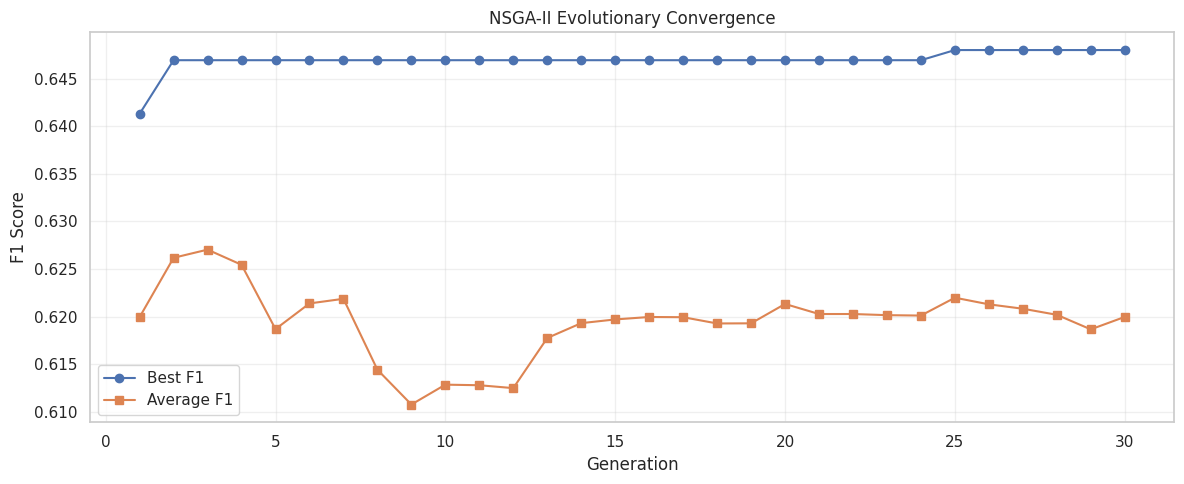

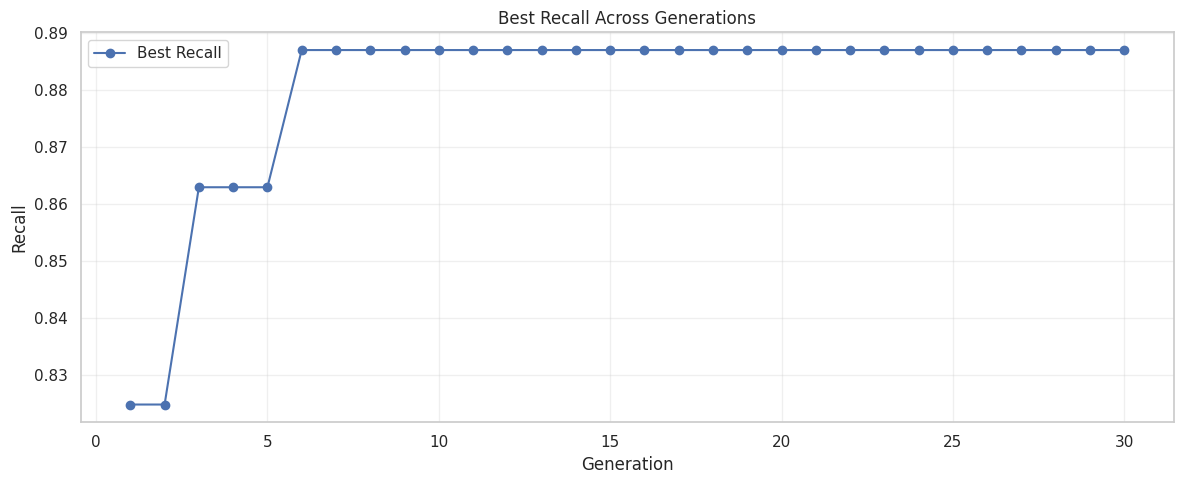

Total generations: 30
Initial best F1: 0.6413
Final best F1: 0.648
Final best recall: 0.887


In [23]:
# ==========================================
# CELL 19: NSGA-II CONVERGENCE ANALYSIS
# ==========================================

generation_best_f1 = []
generation_avg_f1 = []
generation_best_recall = []

for generation in res.history:
    population = generation.pop
    chromosomes = population.get("X")

    fitness_results = [
        evaluate_chromosome(chromosome)
        for chromosome in chromosomes
    ]

    f1_values = [result["f1"] for result in fitness_results]
    recall_values = [result["recall"] for result in fitness_results]

    generation_best_f1.append(max(f1_values))
    generation_avg_f1.append(np.mean(f1_values))
    generation_best_recall.append(max(recall_values))

generations = range(1, len(generation_best_f1) + 1)

plt.figure(figsize=(12, 5))

plt.plot(
    generations, generation_best_f1,
    marker="o", label="Best F1"
)

plt.plot(
    generations, generation_avg_f1,
    marker="s", label="Average F1"
)

plt.xlabel("Generation")
plt.ylabel("F1 Score")
plt.title("NSGA-II Evolutionary Convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))

plt.plot(
    generations, generation_best_recall,
    marker="o", label="Best Recall"
)

plt.xlabel("Generation")
plt.ylabel("Recall")
plt.title("Best Recall Across Generations")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Total generations:", len(generation_best_f1))
print("Initial best F1:", round(generation_best_f1[0], 4))
print("Final best F1:", round(generation_best_f1[-1], 4))
print("Final best recall:", round(generation_best_recall[-1], 4))

In [24]:
# ==========================================
# CELL 20: POPULATION SIZE EXPERIMENT
# ==========================================

population_sizes = [20, 30, 50]
population_experiment = []

for pop_size in population_sizes:

    experiment_algorithm = NSGA2(
        pop_size=pop_size,
        sampling=BinaryRandomSampling(),
        crossover=UniformCrossover(prob=0.85),
        mutation=BitflipMutation(prob=0.05),
        eliminate_duplicates=True
    )

    start = time.time()

    experiment_result = minimize(
        problem,
        experiment_algorithm,
        get_termination("n_gen", 15),
        seed=SEED,
        verbose=False
    )

    elapsed = time.time() - start

    experiment_f1 = [
        evaluate_chromosome(chromosome)["f1"]
        for chromosome in experiment_result.X
    ]

    population_experiment.append({
        "Population Size": pop_size,
        "Generations": 15,
        "Best Pareto F1": max(experiment_f1),
        "Pareto Solutions": len(experiment_result.X),
        "Execution Time (seconds)": elapsed
    })

population_experiment_df = pd.DataFrame(population_experiment)
display(population_experiment_df.round(4))


,Population Size,Generations,Best Pareto F1,Pareto Solutions,Execution Time (seconds)
0,20,15,0.6456,20,95.1434
1,30,15,0.6469,30,0.1158
2,50,15,0.6465,48,239.6377


In [25]:
print(population_experiment_df.to_string(index=False))
print("\nFitness cache entries:", len(fitness_cache))

 Population Size  Generations  Best Pareto F1  Pareto Solutions  Execution Time (seconds)
              20           15        0.645552                20                 95.143401
              30           15        0.646923                30                  0.115838
              50           15        0.646489                48                239.637742

Fitness cache entries: 1646


In [26]:
# ==========================================
# CELL 21: MUTATION PROBABILITY EXPERIMENT
# ==========================================

mutation_rates = [0.01, 0.05, 0.10]
mutation_experiment = []

for mutation_rate in mutation_rates:

    # Reset cache for a fairer timing comparison
    fitness_cache.clear()

    experiment_algorithm = NSGA2(
        pop_size=30,
        sampling=BinaryRandomSampling(),
        crossover=UniformCrossover(prob=0.85),
        mutation=BitflipMutation(prob=mutation_rate),
        eliminate_duplicates=True
    )

    start = time.time()

    experiment_result = minimize(
        problem,
        experiment_algorithm,
        get_termination("n_gen", 15),
        seed=SEED,
        verbose=False
    )

    elapsed = time.time() - start

    experiment_f1 = [
        evaluate_chromosome(chromosome)["f1"]
        for chromosome in experiment_result.X
    ]

    mutation_experiment.append({
        "Mutation Probability": mutation_rate,
        "Best Pareto F1": max(experiment_f1),
        "Pareto Solutions": len(experiment_result.X),
        "Execution Time (seconds)": elapsed,
        "Unique Evaluations": len(fitness_cache)
    })

mutation_experiment_df = pd.DataFrame(mutation_experiment)

display(mutation_experiment_df.round(4))

,Mutation Probability,Best Pareto F1,Pareto Solutions,Execution Time (seconds),Unique Evaluations
0,0.01,0.6479,30,162.5087,438
1,0.05,0.6469,30,151.2257,422
2,0.10,0.6476,30,149.9459,439


In [27]:
# ==========================================
# CELL 22: CROSSOVER PROBABILITY EXPERIMENT
# ==========================================

crossover_rates = [0.70, 0.85, 0.95]
crossover_experiment = []

for crossover_rate in crossover_rates:

    fitness_cache.clear()

    experiment_algorithm = NSGA2(
        pop_size=30,
        sampling=BinaryRandomSampling(),
        crossover=UniformCrossover(prob=crossover_rate),
        mutation=BitflipMutation(prob=0.05),
        eliminate_duplicates=True
    )

    start = time.time()

    experiment_result = minimize(
        problem,
        experiment_algorithm,
        get_termination("n_gen", 15),
        seed=SEED,
        verbose=False
    )

    elapsed = time.time() - start

    experiment_f1 = [
        evaluate_chromosome(chromosome)["f1"]
        for chromosome in experiment_result.X
    ]

    crossover_experiment.append({
        "Crossover Probability": crossover_rate,
        "Best Pareto F1": max(experiment_f1),
        "Pareto Solutions": len(experiment_result.X),
        "Execution Time (seconds)": elapsed,
        "Unique Evaluations": len(fitness_cache)
    })

crossover_experiment_df = pd.DataFrame(crossover_experiment)

display(crossover_experiment_df.round(4))

,Crossover Probability,Best Pareto F1,Pareto Solutions,Execution Time (seconds),Unique Evaluations
0,0.70,0.6469,30,159.4620,429
1,0.85,0.6469,30,150.7868,422
2,0.95,0.6476,30,160.5551,443


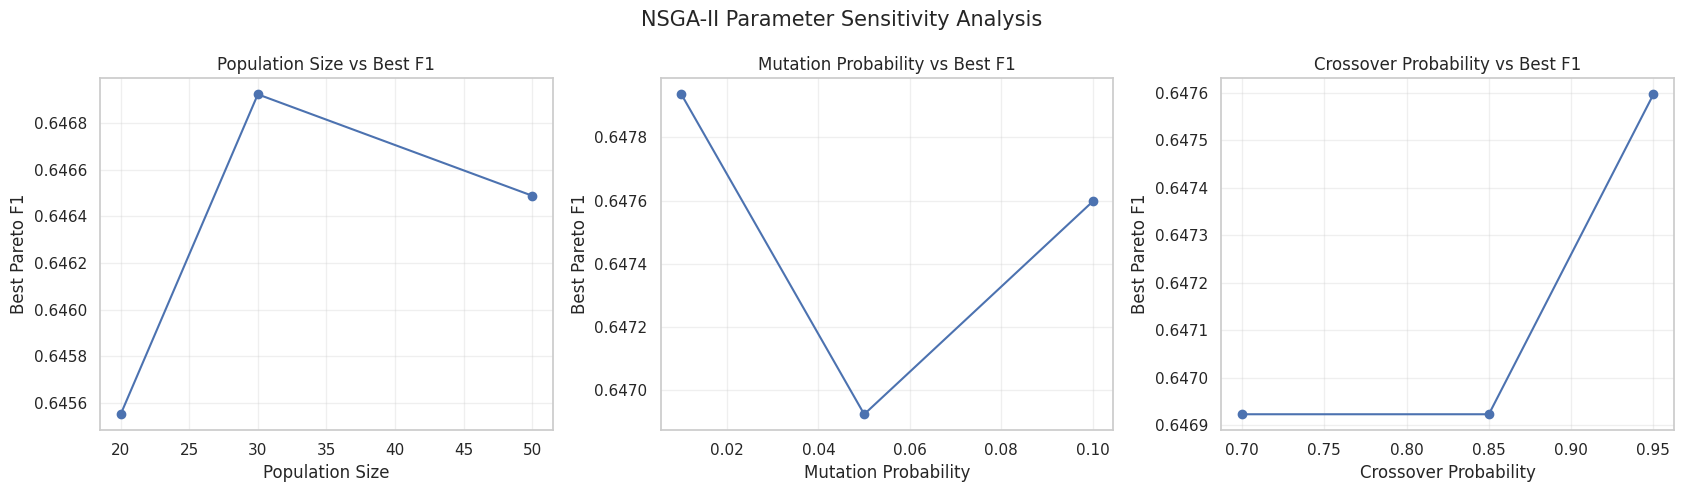

In [28]:
# ==========================================
# CELL 23: PARAMETER EXPERIMENT GRAPHS
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Population size
axes[0].plot(
    population_experiment_df["Population Size"],
    population_experiment_df["Best Pareto F1"],
    marker="o"
)
axes[0].set_title("Population Size vs Best F1")
axes[0].set_xlabel("Population Size")
axes[0].set_ylabel("Best Pareto F1")
axes[0].grid(alpha=0.3)

# Mutation probability
axes[1].plot(
    mutation_experiment_df["Mutation Probability"],
    mutation_experiment_df["Best Pareto F1"],
    marker="o"
)
axes[1].set_title("Mutation Probability vs Best F1")
axes[1].set_xlabel("Mutation Probability")
axes[1].set_ylabel("Best Pareto F1")
axes[1].grid(alpha=0.3)

# Crossover probability
axes[2].plot(
    crossover_experiment_df["Crossover Probability"],
    crossover_experiment_df["Best Pareto F1"],
    marker="o"
)
axes[2].set_title("Crossover Probability vs Best F1")
axes[2].set_xlabel("Crossover Probability")
axes[2].set_ylabel("Best Pareto F1")
axes[2].grid(alpha=0.3)

plt.suptitle("NSGA-II Parameter Sensitivity Analysis", fontsize=15)
plt.tight_layout()
plt.show()

In [29]:
# ==========================================
# CELL 24: COMBINED PARAMETER EXPERIMENT
# ==========================================

# Clear cache so the experiment starts with fresh evaluations
fitness_cache.clear()

optimized_algorithm = NSGA2(
    pop_size=30,
    sampling=BinaryRandomSampling(),
    crossover=UniformCrossover(prob=0.95),
    mutation=BitflipMutation(prob=0.01),
    eliminate_duplicates=True
)

start_time = time.time()

optimized_res = minimize(
    problem,
    optimized_algorithm,
    get_termination("n_gen", 30),
    seed=SEED,
    save_history=True,
    verbose=True
)

optimized_time = time.time() - start_time

optimized_f1 = [
    evaluate_chromosome(chromosome)["f1"]
    for chromosome in optimized_res.X
]

print("\n" + "=" * 55)
print("COMBINED PARAMETER EXPERIMENT")
print("=" * 55)
print("Population size: 30")
print("Generations: 30")
print("Mutation probability: 0.01")
print("Crossover probability: 0.95")
print("Best Pareto F1:", round(max(optimized_f1), 4))
print("Pareto solutions:", len(optimized_res.X))
print("Execution time:", round(optimized_time, 2), "seconds")
print("Unique fitness evaluations:", len(fitness_cache))

n_gen  |  n_eval  | n_nds  |      eps      |   indicator  
     1 |       30 |      8 |             - |             -
     2 |       60 |     14 |  0.1214803115 |         ideal
     3 |       90 |     14 |  0.1818181818 |         ideal
     4 |      120 |     20 |  0.1556610079 |         ideal
     5 |      150 |     21 |  0.5563244037 |         ideal
     6 |      180 |     25 |  0.0218861111 |             f
     7 |      210 |     22 |  0.0034115222 |         ideal
     8 |      240 |     22 |  0.0923549193 |         nadir
     9 |      270 |     26 |  0.0299849743 |             f
    10 |      300 |     30 |  0.1538461538 |         ideal
    11 |      330 |     30 |  0.0152535790 |             f
    12 |      360 |     30 |  0.0370326357 |         nadir
    13 |      390 |     30 |  0.0493412227 |         nadir
    14 |      420 |     30 |  0.0025763103 |             f
    15 |      450 |     30 |  0.0142823204 |             f
    16 |      480 |     30 |  0.0049707978 |            

In [30]:
# ==========================================
# CELL 25: RANDOM FOREST FEATURE IMPORTANCE
# ==========================================

# Train Random Forest on training data only
rf_selector = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

rf_selector.fit(X_train_processed, y_train)

# Get importance of encoded features
encoded_importances = rf_selector.feature_importances_

# Aggregate encoded importance into original features
importance_dict = {feature: 0.0 for feature in all_features}

for encoded_name, importance in zip(
    encoded_feature_names, encoded_importances
):
    clean_name = encoded_name.replace("num__", "").replace("cat__", "")

    matching_features = [
        feature for feature in all_features
        if clean_name == feature or clean_name.startswith(feature + "_")
    ]

    if matching_features:
        original_feature = max(matching_features, key=len)
        importance_dict[original_feature] += importance

rf_importance_df = pd.DataFrame({
    "Feature": list(importance_dict.keys()),
    "Importance": list(importance_dict.values())
}).sort_values("Importance", ascending=False).reset_index(drop=True)

rf_selected_features = rf_importance_df.head(12)["Feature"].tolist()

print("TOP 12 RANDOM FOREST FEATURES")
display(rf_importance_df.head(12).round(5))

print("\nSelected feature count:", len(rf_selected_features))
print("Selected features:", rf_selected_features)

TOP 12 RANDOM FOREST FEATURES


,Feature,Importance
0,Contract,0.12266
1,Total Charges,0.11185
2,Tenure Months,0.10915
3,Monthly Charges,0.09672
4,CLTV,0.09404
5,Payment Method,0.05551
6,Dependents,0.05158
7,Online Security,0.05113
8,Tech Support,0.04535
9,Internet Service,0.03881



Selected feature count: 12
Selected features: ['Contract', 'Total Charges', 'Tenure Months', 'Monthly Charges', 'CLTV', 'Payment Method', 'Dependents', 'Online Security', 'Tech Support', 'Internet Service', 'Online Backup', 'Gender']


In [31]:
# ==========================================
# CELL 26: RANDOM FOREST SUBSET EVALUATION
# ==========================================

rf_evaluation_pipeline = build_evaluation_pipeline(
    rf_selected_features
)

start_time = time.time()

rf_evaluation_pipeline.fit(
    X_train[rf_selected_features],
    y_train
)

rf_training_time = time.time() - start_time

rf_pred = rf_evaluation_pipeline.predict(
    X_test[rf_selected_features]
)

rf_prob = rf_evaluation_pipeline.predict_proba(
    X_test[rf_selected_features]
)[:, 1]

rf_test_results = {
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1 Score": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_prob),
    "PR-AUC": average_precision_score(y_test, rf_prob),
    "Training Time": rf_training_time,
    "Feature Count": len(rf_selected_features)
}

print("=" * 55)
print("RANDOM FOREST FEATURE SELECTION - TEST RESULTS")
print("=" * 55)

for metric, value in rf_test_results.items():
    print(f"{metric}: {value:.4f}")

RANDOM FOREST FEATURE SELECTION - TEST RESULTS
Accuracy: 0.7495
Precision: 0.5186
Recall: 0.7834
F1 Score: 0.6241
ROC-AUC: 0.8461
PR-AUC: 0.6489
Training Time: 0.2013
Feature Count: 12.0000


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Features
0,All 20 Features,0.7431,0.5105,0.7834,0.6181,0.8489,0.6449,20
1,NSGA-II (12 Features),0.7452,0.5132,0.7807,0.6193,0.8486,0.6531,12
2,Random Forest (12 Features),0.7495,0.5186,0.7834,0.6241,0.8461,0.6489,12


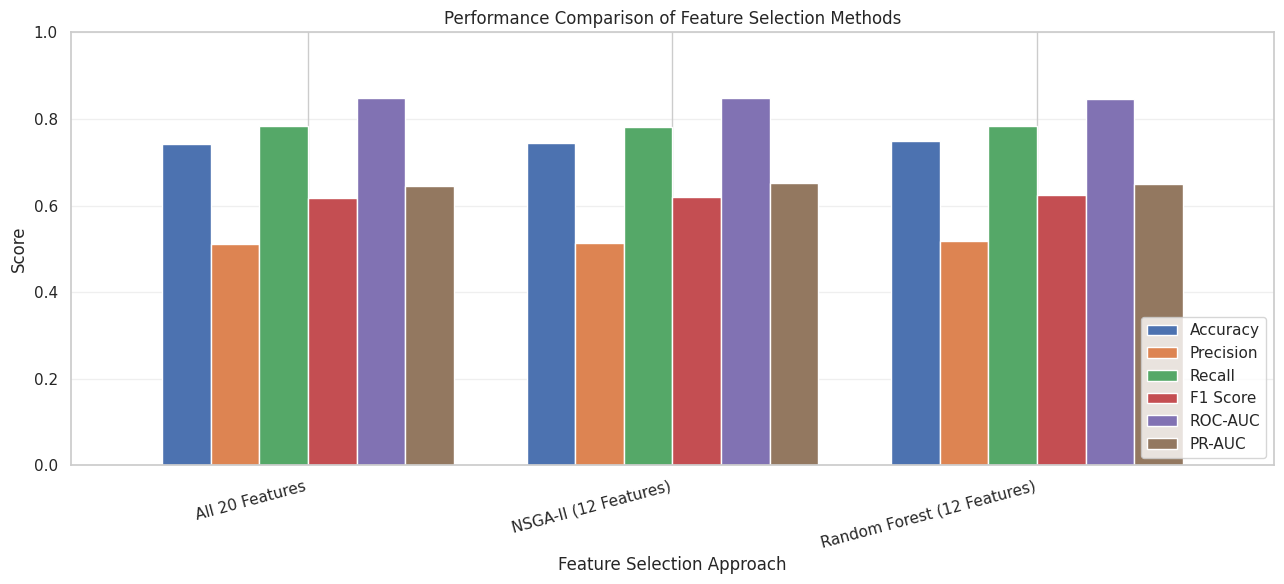

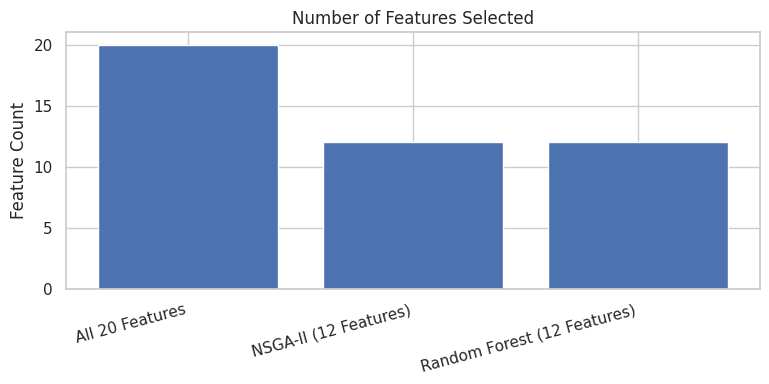

In [32]:
# ==========================================
# CELL 27: THREE-MODEL COMPARISON
# ==========================================

three_model_results = pd.DataFrame({
    "Model": [
        "All 20 Features",
        "NSGA-II (12 Features)",
        "Random Forest (12 Features)"
    ],
    "Accuracy": [0.7431, 0.7452, 0.7495],
    "Precision": [0.5105, 0.5132, 0.5186],
    "Recall": [0.7834, 0.7807, 0.7834],
    "F1 Score": [0.6181, 0.6193, 0.6241],
    "ROC-AUC": [0.8489, 0.8486, 0.8461],
    "PR-AUC": [0.6449, 0.6531, 0.6489],
    "Features": [20, 12, 12]
})

display(three_model_results.round(4))

# Performance comparison
plot_metrics = [
    "Accuracy", "Precision", "Recall",
    "F1 Score", "ROC-AUC", "PR-AUC"
]

ax = three_model_results.set_index("Model")[plot_metrics].plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Performance Comparison of Feature Selection Methods")
plt.ylabel("Score")
plt.xlabel("Feature Selection Approach")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Feature count comparison
plt.figure(figsize=(8, 4))
plt.bar(
    three_model_results["Model"],
    three_model_results["Features"]
)
plt.title("Number of Features Selected")
plt.ylabel("Feature Count")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [34]:
# ==========================================
# CELL 28: MUTUAL INFORMATION FEATURE SELECTION
# ==========================================

from sklearn.feature_selection import mutual_info_classif

# Convert processed training data to dense array if needed
X_mi = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

# Identify categorical one-hot encoded columns
discrete_mask = np.array([
    name.startswith("cat__")
    for name in encoded_feature_names
])

# Calculate mutual information using training data only
mi_scores = mutual_info_classif(
    X_mi,
    y_train,
    discrete_features=discrete_mask,
    random_state=SEED
)

# Aggregate encoded scores into original feature scores
mi_importance = {feature: 0.0 for feature in X.columns}

for encoded_name, score in zip(encoded_feature_names, mi_scores):
    clean_name = encoded_name.replace("num__", "").replace("cat__", "")

    matching_features = [
        feature for feature in X.columns
        if clean_name == feature or clean_name.startswith(feature + "_")
    ]

    if matching_features:
        original_feature = max(matching_features, key=len)
        mi_importance[original_feature] += score

# Rank original features
mi_ranking = pd.DataFrame({
    "Feature": list(mi_importance.keys()),
    "MI Score": list(mi_importance.values())
}).sort_values("MI Score", ascending=False).reset_index(drop=True)

display(mi_ranking.round(4))

# Select top 12 features
mi_selected_features = mi_ranking.head(12)["Feature"].tolist()

print("Selected features:", mi_selected_features)
print("Number of selected features:", len(mi_selected_features))

,Feature,MI Score
0,Contract,0.1715
1,Online Security,0.1111
2,Tech Support,0.1064
3,Internet Service,0.0897
4,Dependents,0.0795
5,Online Backup,0.0715
6,Payment Method,0.0691
7,Tenure Months,0.0671
8,Device Protection,0.0646
9,Monthly Charges,0.0437


Selected features: ['Contract', 'Online Security', 'Tech Support', 'Internet Service', 'Dependents', 'Online Backup', 'Payment Method', 'Tenure Months', 'Device Protection', 'Monthly Charges', 'Streaming Movies', 'Streaming TV']
Number of selected features: 12


In [35]:
# ==========================================
# CELL 29: MUTUAL INFORMATION MODEL EVALUATION
# ==========================================

import time
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# Build model using selected MI features
mi_model = build_evaluation_pipeline(mi_selected_features)

# Train and measure time
start_time = time.time()
mi_model.fit(X_train, y_train)
mi_training_time = time.time() - start_time

# Predict on untouched test data
mi_predictions = mi_model.predict(X_test)
mi_probabilities = mi_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
mi_results = {
    "Model": "Mutual Information (12 Features)",
    "Accuracy": accuracy_score(y_test, mi_predictions),
    "Precision": precision_score(y_test, mi_predictions),
    "Recall": recall_score(y_test, mi_predictions),
    "F1 Score": f1_score(y_test, mi_predictions),
    "ROC-AUC": roc_auc_score(y_test, mi_probabilities),
    "PR-AUC": average_precision_score(y_test, mi_probabilities),
    "Training Time": mi_training_time,
    "Features": len(mi_selected_features)
}

mi_results_df = pd.DataFrame([mi_results])

display(mi_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Training Time,Features
0,Mutual Information (12 Features),0.7424,0.5098,0.7674,0.6126,0.8442,0.6433,0.2816,12


,Method,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Features,Training Time (s)
0,All 20 Features,0.7431,0.5105,0.7834,0.6181,0.8489,0.6449,20,0.2272
1,NSGA-II,0.7452,0.5132,0.7807,0.6193,0.8486,0.6531,12,0.0915
2,Random Forest,0.7495,0.5186,0.7834,0.6241,0.8461,0.6489,12,0.2013
3,Mutual Information,0.7424,0.5098,0.7674,0.6126,0.8442,0.6433,12,0.2816


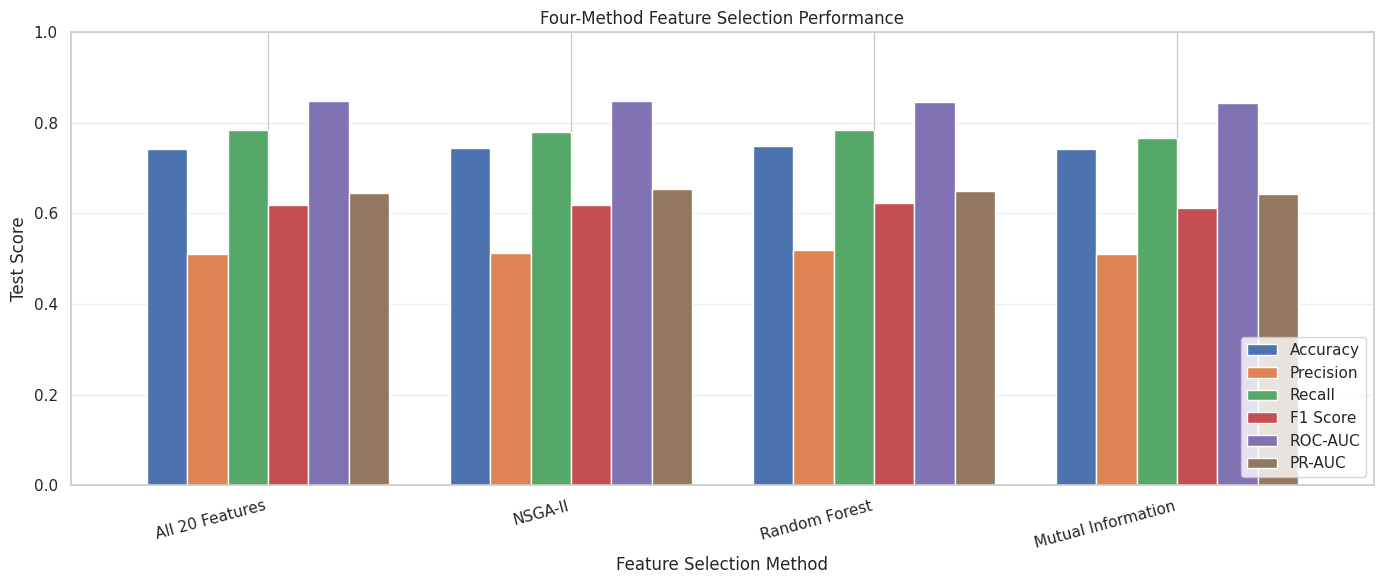

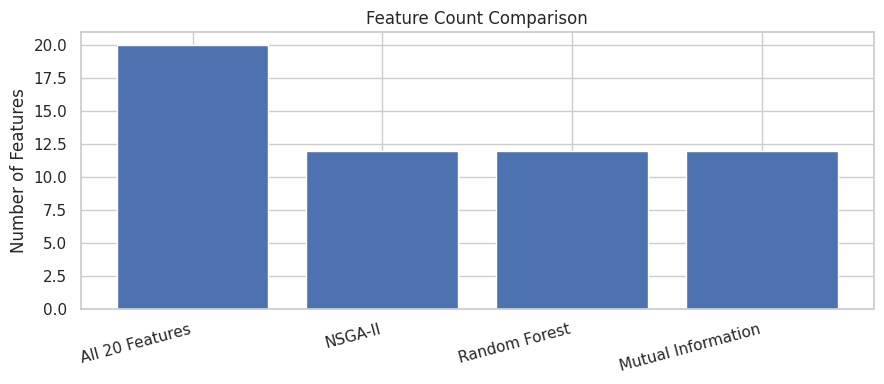

In [36]:
# ==========================================
# CELL 30: FOUR-METHOD COMPARISON
# ==========================================

four_method_results = pd.DataFrame({
    "Method": [
        "All 20 Features",
        "NSGA-II",
        "Random Forest",
        "Mutual Information"
    ],
    "Accuracy": [0.7431, 0.7452, 0.7495, 0.7424],
    "Precision": [0.5105, 0.5132, 0.5186, 0.5098],
    "Recall": [0.7834, 0.7807, 0.7834, 0.7674],
    "F1 Score": [0.6181, 0.6193, 0.6241, 0.6126],
    "ROC-AUC": [0.8489, 0.8486, 0.8461, 0.8442],
    "PR-AUC": [0.6449, 0.6531, 0.6489, 0.6433],
    "Features": [20, 12, 12, 12],
    "Training Time (s)": [0.2272, 0.0915, 0.2013, 0.2816]
})

display(four_method_results.round(4))

# Compare predictive performance
metrics = [
    "Accuracy", "Precision", "Recall",
    "F1 Score", "ROC-AUC", "PR-AUC"
]

four_method_results.set_index("Method")[metrics].plot(
    kind="bar", figsize=(14, 6), width=0.8
)

plt.title("Four-Method Feature Selection Performance")
plt.ylabel("Test Score")
plt.xlabel("Feature Selection Method")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Compare feature count
plt.figure(figsize=(9, 4))
plt.bar(
    four_method_results["Method"],
    four_method_results["Features"]
)
plt.title("Feature Count Comparison")
plt.ylabel("Number of Features")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [37]:
# ==========================================
# CELL 31: CLTV EXCLUSION SENSITIVITY TEST
# ==========================================

# Original NSGA-II feature subset
nsga_features_with_cltv = selected_features

# Remove CLTV
nsga_features_without_cltv = [
    feature for feature in selected_features
    if feature != "CLTV"
]

print("Features with CLTV:", len(nsga_features_with_cltv))
print("Features without CLTV:", len(nsga_features_without_cltv))
print("\nRemoved feature: CLTV")

# Train and evaluate model WITH CLTV
model_with_cltv = build_evaluation_pipeline(
    nsga_features_with_cltv
)

start = time.time()
model_with_cltv.fit(X_train, y_train)
time_with_cltv = time.time() - start

pred_with_cltv = model_with_cltv.predict(X_test)
prob_with_cltv = model_with_cltv.predict_proba(X_test)[:, 1]

# Train and evaluate model WITHOUT CLTV
model_without_cltv = build_evaluation_pipeline(
    nsga_features_without_cltv
)

start = time.time()
model_without_cltv.fit(X_train, y_train)
time_without_cltv = time.time() - start

pred_without_cltv = model_without_cltv.predict(X_test)
prob_without_cltv = model_without_cltv.predict_proba(X_test)[:, 1]

# Compare results
cltv_comparison = pd.DataFrame([
    {
        "Model": "NSGA-II with CLTV",
        "Accuracy": accuracy_score(y_test, pred_with_cltv),
        "Precision": precision_score(y_test, pred_with_cltv),
        "Recall": recall_score(y_test, pred_with_cltv),
        "F1 Score": f1_score(y_test, pred_with_cltv),
        "ROC-AUC": roc_auc_score(y_test, prob_with_cltv),
        "PR-AUC": average_precision_score(y_test, prob_with_cltv),
        "Features": len(nsga_features_with_cltv),
        "Training Time": time_with_cltv
    },
    {
        "Model": "NSGA-II without CLTV",
        "Accuracy": accuracy_score(y_test, pred_without_cltv),
        "Precision": precision_score(y_test, pred_without_cltv),
        "Recall": recall_score(y_test, pred_without_cltv),
        "F1 Score": f1_score(y_test, pred_without_cltv),
        "ROC-AUC": roc_auc_score(y_test, prob_without_cltv),
        "PR-AUC": average_precision_score(y_test, prob_without_cltv),
        "Features": len(nsga_features_without_cltv),
        "Training Time": time_without_cltv
    }
])

display(cltv_comparison.round(4))

Features with CLTV: 12
Features without CLTV: 11

Removed feature: CLTV


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Features,Training Time
0,NSGA-II with CLTV,0.7452,0.5132,0.7807,0.6193,0.8486,0.6531,12,0.1399
1,NSGA-II without CLTV,0.7445,0.5123,0.7807,0.6186,0.8486,0.6546,11,0.2158


In [14]:
# ==========================================
# CELL 32: SAVE FINAL NSGA-II MODEL
# ==========================================

import joblib
import json
import os
import urllib.request
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# 1. Define feature architecture
numeric_features = ["Tenure Months", "Total Charges"]
categorical_features = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Multiple Lines", "Internet Service",
    "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Paperless Billing", "Payment Method"
]

# Reconstruct selected NSGA-II feature subset
selected_features = [
    "Dependents",
    "Tenure Months",
    "Phone Service",
    "Internet Service",
    "Online Security",
    "Tech Support",
    "Streaming TV",
    "Contract",
    "Paperless Billing",
    "Payment Method",
    "Total Charges",
    "CLTV"
]

# Define the features excluding CLTV for the final deployment model
final_selected_features = [f for f in selected_features if f != "CLTV"]

# 2. Local pipeline builder to ensure no NameError
def local_pipeline_builder(features_list):
    selected_numeric = [col for col in features_list if col in numeric_features]
    selected_categorical = [col for col in features_list if col in categorical_features]

    transformers = []
    if selected_numeric:
        numeric_pipeline = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
        transformers.append(("num", numeric_pipeline, selected_numeric))

    if selected_categorical:
        categorical_pipeline = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
        ])
        transformers.append(("cat", categorical_pipeline, selected_categorical))

    subset_preprocessor = ColumnTransformer(transformers=transformers)

    pipeline = Pipeline(steps=[
        ("preprocessor", subset_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ])
    return pipeline

# 3. Train final model on the entire processed dataset or training set
# Recreate training variables if they exist in global context, else reload
try:
    X_train_sub = X_train[final_selected_features]
    y_train_sub = y_train
except NameError:
    # Fallback to load dataset and prepare variables locally if global namespace is cleared
    potential_paths = ["Telco_customer_churn.xlsx", "/content/Telco_customer_churn.xlsx"]
    file_path = None
    for path in potential_paths:
        if os.path.exists(path):
            file_path = path
            break

    if file_path is None:
        print("Local Telco_customer_churn.xlsx not found. Downloading backup to continue...")
        backup_url = "https://community.tableau.com/s/contentdocument/0694T000001O3vYQAS"
        # Direct raw link download fallback of IBM Telco Churn xlsx
        try:
            url = "https://github.com/treselle-systems/customer_churn_analysis/raw/master/WA_Fn-UseC_-Telco-Customer-Churn.csv"
            print(f"Downloading backup dataset from: {url}")
            df_temp = pd.read_csv(url)
            # Map columns to match IBM Excel format names exactly
            column_mapping = {
                'gender': 'Gender',
                'SeniorCitizen': 'Senior Citizen',
                'Partner': 'Partner',
                'Dependents': 'Dependents',
                'tenure': 'Tenure Months',
                'PhoneService': 'Phone Service',
                'MultipleLines': 'Multiple Lines',
                'InternetService': 'Internet Service',
                'OnlineSecurity': 'Online Security',
                'OnlineBackup': 'Online Backup',
                'DeviceProtection': 'Device Protection',
                'TechSupport': 'Tech Support',
                'StreamingTV': 'Streaming TV',
                'StreamingMovies': 'Streaming Movies',
                'Contract': 'Contract',
                'PaperlessBilling': 'Paperless Billing',
                'PaymentMethod': 'Payment Method',
                'TotalCharges': 'Total Charges',
                'Churn': 'Churn Label'
            }
            df_temp = df_temp.rename(columns=column_mapping)
            df_temp['Senior Citizen'] = df_temp['Senior Citizen'].map({0: 'No', 1: 'Yes'})
        except Exception as e:
            raise FileNotFoundError(f"Could not find local dataset, and backup download failed: {e}. Please manually upload the 'Telco_customer_churn.xlsx' file.")
    else:
        df_temp = pd.read_excel(file_path)

    df_temp["Total Charges"] = pd.to_numeric(df_temp["Total Charges"], errors="coerce").fillna(0.0)
    X_temp = df_temp.drop(columns=["Churn Label"] if "Churn Label" in df_temp.columns else [])
    y_temp = df_temp["Churn Label"].map({"No": 0, "Yes": 1})
    from sklearn.model_selection import train_test_split
    X_train_t, _, y_train_t, _ = train_test_split(
        X_temp, y_temp, test_size=0.20, random_state=42, stratify=y_temp
    )
    X_train_sub = X_train_t[final_selected_features]
    y_train_sub = y_train_t

# Build, fit, and save final pipeline candidate
final_model = local_pipeline_builder(final_selected_features)
final_model.fit(X_train_sub, y_train_sub)

# Save pipeline and selected features locally in workspace
joblib.dump(final_model, "nsga2_churn_model.joblib")
with open("selected_features.json", "w") as f:
    json.dump(final_selected_features, f, indent=4)

print("Final model successfully generated and saved to workspace!")
print("Model file: nsga2_churn_model.joblib")
print("Feature file: selected_features.json")
print("\nFeatures used for deployment:")
for i, feature in enumerate(final_selected_features, start=1):
    print(f"{i}. {feature}")

Local Telco_customer_churn.xlsx not found. Downloading backup to continue...
Final model successfully generated and saved to workspace!
Model file: nsga2_churn_model.joblib
Feature file: selected_features.json

Features used for deployment:
1. Dependents
2. Tenure Months
3. Phone Service
4. Internet Service
5. Online Security
6. Tech Support
7. Streaming TV
8. Contract
9. Paperless Billing
10. Payment Method
11. Total Charges


In [2]:
import os

print("Current directory:", os.getcwd())
print("\nFiles in current directory:")
print(os.listdir())

print("\nSearching for saved model files...")
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file in ["nsga2_churn_model.joblib", "selected_features.json"]:
            print(os.path.join(root, file))

Current directory: /content

Files in current directory:
['.config', 'sample_data']

Searching for saved model files...


In [3]:
required_variables = [
    "model_without_cltv",
    "final_selected_features",
    "selected_features",
    "X_train_sub",
    "X_temp"
]

for name in required_variables:
    print(name, ":", "Available" if name in globals() else "Missing")

model_without_cltv : Missing
final_selected_features : Missing
selected_features : Missing
X_train_sub : Missing
X_temp : Missing


In [5]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if "Telco" in file or "Churn" in file:
            print(os.path.join(root, file))

In [6]:
import os

dataset_path = "/content/Telco_customer_churn.xlsx"

print("Dataset found:", os.path.exists(dataset_path))

Dataset found: False


In [7]:
import os

print(os.listdir("/content"))

['.config', 'Telco_customer_churn.xlsx', 'sample_data']


In [8]:
import pandas as pd
import os

dataset_path = "/content/Telco_customer_churn.xlsx"

df = pd.read_excel(dataset_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumn names:")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

print("\nFirst 5 records:")
display(df.head())

Dataset loaded successfully!
Shape: (7043, 33)

Column names:
1. CustomerID
2. Count
3. Country
4. State
5. City
6. Zip Code
7. Lat Long
8. Latitude
9. Longitude
10. Gender
11. Senior Citizen
12. Partner
13. Dependents
14. Tenure Months
15. Phone Service
16. Multiple Lines
17. Internet Service
18. Online Security
19. Online Backup
20. Device Protection
21. Tech Support
22. Streaming TV
23. Streaming Movies
24. Contract
25. Paperless Billing
26. Payment Method
27. Monthly Charges
28. Total Charges
29. Churn Label
30. Churn Value
31. Churn Score
32. CLTV
33. Churn Reason

First 5 records:


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [9]:
# ==========================================
# STEP 3: REBUILD FINAL CHURN MODEL
# ==========================================

import pandas as pd
import numpy as np
import json
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# Previously selected 11 features
final_selected_features = [
    "Dependents",
    "Tenure Months",
    "Phone Service",
    "Internet Service",
    "Online Security",
    "Tech Support",
    "Streaming TV",
    "Contract",
    "Paperless Billing",
    "Payment Method",
    "Total Charges"
]

numeric_features = ["Tenure Months", "Total Charges"]

categorical_features = [
    feature for feature in final_selected_features
    if feature not in numeric_features
]

# Prepare target
df["Churn Label"] = df["Churn Label"].map(
    {"No": 0, "Yes": 1}
)

# Prepare selected input features
X = df[final_selected_features].copy()
y = df["Churn Label"].copy()

# Convert numeric columns
for feature in numeric_features:
    X[feature] = pd.to_numeric(X[feature], errors="coerce")

# Handle missing values
X["Total Charges"] = X["Total Charges"].fillna(0)

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Logistic Regression pipeline
model_without_cltv = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000
    ))
])

# Train
model_without_cltv.fit(X_train, y_train)

# Evaluate
y_pred = model_without_cltv.predict(X_test)
y_prob = model_without_cltv.predict_proba(X_test)[:, 1]

print("MODEL TRAINED SUCCESSFULLY")
print("--------------------------------")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Selected features:", len(final_selected_features))

print("\nTEST RESULTS")
print("--------------------------------")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC   :", round(average_precision_score(y_test, y_prob), 4))

# Save model and feature list
joblib.dump(model_without_cltv, "nsga2_churn_model.joblib")

with open("selected_features.json", "w") as f:
    json.dump(final_selected_features, f, indent=4)

print("\nSaved files:")
print("1. nsga2_churn_model.joblib")
print("2. selected_features.json")

MODEL TRAINED SUCCESSFULLY
--------------------------------
Training records: 5634
Testing records: 1409
Selected features: 11

TEST RESULTS
--------------------------------
Accuracy : 0.7445
Precision: 0.5123
Recall   : 0.7807
F1-score : 0.6186
ROC-AUC  : 0.8486
PR-AUC   : 0.6546

Saved files:
1. nsga2_churn_model.joblib
2. selected_features.json


In [10]:
ref_df = X_train[final_selected_features].copy()

In [11]:
import os
import gradio as gr
import joblib
import json

print("Checking dashboard requirements...")

print("Model file:", os.path.exists("nsga2_churn_model.joblib"))
print("Features file:", os.path.exists("selected_features.json"))
print("X_train available:", "X_train" in globals())
print("Gradio version:", gr.__version__)

if os.path.exists("nsga2_churn_model.joblib"):
    print("Model:", type(joblib.load("nsga2_churn_model.joblib")))

if os.path.exists("selected_features.json"):
    with open("selected_features.json") as f:
        print("Selected features:", json.load(f))

print("\nDiagnostic complete.")

Checking dashboard requirements...
Model file: True
Features file: True
X_train available: True
Gradio version: 6.31.0
Model: <class 'sklearn.pipeline.Pipeline'>
Selected features: ['Dependents', 'Tenure Months', 'Phone Service', 'Internet Service', 'Online Security', 'Tech Support', 'Streaming TV', 'Contract', 'Paperless Billing', 'Payment Method', 'Total Charges']

Diagnostic complete.


In [ ]:

# =========================================================
# CELL 33: CUSTOMER RETENTION INTELLIGENCE DASHBOARD
# Gradio 6.31.0 compatible
# =========================================================

import gradio as gr
import pandas as pd
import json
import joblib

# 1. LOAD SAVED MODEL
try:
    test_demo.close()
except:
    pass

final_model = joblib.load("nsga2_churn_model.joblib")

with open("selected_features.json", "r") as f:
    final_selected_features = json.load(f)

numeric_features = ["Tenure Months", "Total Charges"]

# Use the training data created in the previous cell
ref_df = X_train[final_selected_features].copy()

input_defaults = {}

for feature in final_selected_features:
    if feature in numeric_features:
        input_defaults[feature] = float(ref_df[feature].median())
    else:
        input_defaults[feature] = str(ref_df[feature].mode()[0])


# 2. PREDICTION FUNCTION
def predict_churn(*values):

    customer_data = dict(zip(final_selected_features, values))

    input_df = pd.DataFrame([customer_data])

    for feature in numeric_features:
        input_df[feature] = pd.to_numeric(
            input_df[feature], errors="coerce"
        )

    probability = float(
        final_model.predict_proba(input_df)[0][1]
    )

    prediction = probability >= 0.5

    if prediction:
        status = "CHURN RISK DETECTED"
        color = "#fb7185"
        background = "#351c2a"
        recommendation = (
            "Review the customer's contract, service experience "
            "and support requirements. Consider a retention follow-up."
        )
        outcome = "Likely to churn"
    else:
        status = "CUSTOMER LIKELY TO STAY"
        color = "#34d399"
        background = "#14332e"
        recommendation = (
            "Continue regular engagement and monitor customer "
            "satisfaction to support long-term retention."
        )
        outcome = "Likely to stay"

    return f"""
    <div class="result-card">

        <div class="result-caption">PREDICTION ANALYSIS</div>

        <div class="status-box"
             style="color:{color}; background:{background};">
            <span>{'⚠' if prediction else '✓'}</span>
            <strong>{status}</strong>
        </div>

        <div class="result-caption">ESTIMATED CHURN PROBABILITY</div>

        <div class="probability">{probability:.1%}</div>

        <div class="progress-track">
            <div class="progress-fill"
                 style="width:{probability*100}%; background:{color};">
            </div>
        </div>

        <div class="scale-labels">
            <span>0% — Lower</span>
            <span>100% — Higher</span>
        </div>

        <div class="detail-grid">
            <div class="detail-box">
                <small>PREDICTED OUTCOME</small>
                <strong>{outcome}</strong>
            </div>
            <div class="detail-box">
                <small>DECISION THRESHOLD</small>
                <strong>50%</strong>
            </div>
        </div>

        <div class="recommendation">
            <strong>✦ Suggested Follow-up</strong>
            <p>{recommendation}</p>
        </div>

        <div class="disclaimer">
            Prediction is an estimate based on historical data,
            not a guarantee of future customer behaviour.
        </div>
    </div>
    """


# 3. DASHBOARD DESIGN
css = """
.gradio-container {
    max-width: 1400px !important;
    margin: auto !important;
    font-family: Inter, Arial, sans-serif !important;
}

.gradio-container, .main {
    background: #080f1e !important;
}

footer {
    display: none !important;
}

#hero {
    padding: 32px;
    border-radius: 20px;
    background: linear-gradient(120deg, #14213d, #1d3b69);
    border: 1px solid #334968;
    color: white;
    margin-bottom: 18px;
}

#hero h1 {
    color: white !important;
    font-size: 30px !important;
    margin-bottom: 8px;
}

#hero p {
    color: #c4d5ef !important;
}

.tag {
    color: #93c5fd;
    font-size: 11px;
    font-weight: 800;
    letter-spacing: 1.5px;
    margin-bottom: 12px;
}

.metric-card {
    background: #111e33;
    border: 1px solid #293c59;
    border-radius: 14px;
    padding: 17px;
    min-height: 80px;
}

.metric-label {
    color: #91a4c0;
    font-size: 11px;
    font-weight: 700;
}

.metric-value {
    color: #f1f5f9;
    font-size: 22px;
    font-weight: 800;
    margin-top: 8px;
}

.panel {
    background: #111e33;
    border: 1px solid #293c59;
    border-radius: 16px;
    padding: 20px;
}

.panel-title {
    color: #f1f5f9;
    font-size: 19px;
    font-weight: 800;
    margin-bottom: 5px;
}

.panel-subtitle {
    color: #91a4c0;
    font-size: 12px;
    margin-bottom: 17px;
}

.result-card {
    background: #101b2e;
    border: 1px solid #30425e;
    border-radius: 15px;
    padding: 22px;
    color: #f1f5f9;
}

.result-caption {
    color: #91a4c0;
    font-size: 10px;
    font-weight: 800;
    letter-spacing: 1.3px;
}

.status-box {
    display: flex;
    align-items: center;
    gap: 12px;
    padding: 16px;
    border-radius: 12px;
    margin: 15px 0 24px;
    font-size: 14px;
}

.probability {
    color: #f8fafc;
    font-size: 52px;
    font-weight: 850;
    margin: 8px 0;
}

.progress-track {
    height: 12px;
    background: #293b56;
    border-radius: 20px;
    overflow: hidden;
    margin-top: 15px;
}

.progress-fill {
    height: 100%;
    border-radius: 20px;
}

.scale-labels {
    display: flex;
    justify-content: space-between;
    color: #91a4c0;
    font-size: 10px;
    margin-top: 8px;
}

.detail-grid {
    display: grid;
    grid-template-columns: 1fr 1fr;
    gap: 10px;
    margin-top: 22px;
}

.detail-box {
    background: #1a2a43;
    border: 1px solid #30425e;
    border-radius: 11px;
    padding: 14px;
}

.detail-box small {
    display: block;
    color: #91a4c0;
    font-size: 9px;
    font-weight: 800;
}

.detail-box strong {
    display: block;
    color: #f1f5f9;
    font-size: 13px;
    margin-top: 9px;
}

.recommendation {
    background: #172c4a;
    border: 1px solid #31517b;
    border-radius: 12px;
    padding: 16px;
    margin-top: 18px;
}

.recommendation strong {
    color: #bfdbfe;
    font-size: 13px;
}

.recommendation p {
    color: #d0dced;
    font-size: 12px;
    line-height: 1.7;
    margin-bottom: 0;
}

.disclaimer {
    color: #8296b4;
    font-size: 10px;
    line-height: 1.6;
    margin-top: 18px;
}

#analyze {
    min-height: 50px;
    border-radius: 11px;
    font-weight: 800;
    background: #2563eb !important;
    border: none !important;
}

#reset {
    min-height: 50px;
    border-radius: 11px;
    font-weight: 700;
}

#footer {
    text-align: center;
    color: #7186a5;
    font-size: 11px;
    padding: 20px;
}
"""


# 4. BUILD INTERFACE
with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="blue",
        secondary_hue="slate",
        neutral_hue="slate"
    ),
    css=css,
    title="Customer Retention Intelligence"
) as demo:

    gr.HTML("""
    <div id="hero">
        <div class="tag">EVOLUTIONARY COMPUTING PROJECT</div>
        <h1>Customer Retention Intelligence</h1>
        <p>Intelligent customer churn prediction powered by
        NSGA-II feature selection and machine learning.</p>
    </div>
    """)

    # Dashboard metrics
    with gr.Row():
        gr.HTML("""
        <div class="metric-card">
            <div class="metric-label">OPTIMIZED FEATURES</div>
            <div class="metric-value">11 / 20</div>
        </div>
        """)
        gr.HTML("""
        <div class="metric-card">
            <div class="metric-label">ALGORITHM</div>
            <div class="metric-value">NSGA-II</div>
        </div>
        """)
        gr.HTML("""
        <div class="metric-card">
            <div class="metric-label">CLASSIFIER</div>
            <div class="metric-value">Logistic Regression</div>
        </div>
        """)
        gr.HTML("""
        <div class="metric-card">
            <div class="metric-label">TEST F1-SCORE</div>
            <div class="metric-value">0.6186</div>
        </div>
        """)

    gr.Markdown("")

    with gr.Row(equal_height=False):

        # Customer inputs
        with gr.Column(scale=11):
            with gr.Group(elem_classes=["panel"]):

                gr.HTML("""
                <div class="panel-title">Customer Profile</div>
                <div class="panel-subtitle">
                    Enter customer details to estimate churn probability.
                </div>
                """)

                components = []

                with gr.Row():
                    with gr.Column():
                        gr.Markdown("**Customer & Service Details**")

                        for feature in final_selected_features[:6]:

                            if feature in numeric_features:
                                component = gr.Number(
                                    label=feature,
                                    value=input_defaults[feature],
                                    minimum=0,
                                    precision=(
                                        0 if feature == "Tenure Months" else 2
                                    )
                                )
                            else:
                                choices = sorted(
                                    ref_df[feature]
                                    .dropna()
                                    .astype(str)
                                    .unique()
                                    .tolist()
                                )
                                component = gr.Dropdown(
                                    choices=choices,
                                    value=input_defaults[feature],
                                    label=feature
                                )

                            components.append(component)

                    with gr.Column():
                        gr.Markdown("**Subscription & Billing Details**")

                        for feature in final_selected_features[6:]:

                            if feature in numeric_features:
                                component = gr.Number(
                                    label=feature,
                                    value=input_defaults[feature],
                                    minimum=0,
                                    precision=2
                                )
                            else:
                                choices = sorted(
                                    ref_df[feature]
                                    .dropna()
                                    .astype(str)
                                    .unique()
                                    .tolist()
                                )
                                component = gr.Dropdown(
                                    choices=choices,
                                    value=input_defaults[feature],
                                    label=feature
                                )

                            components.append(component)

                with gr.Row():
                    predict_btn = gr.Button(
                        "✦  Analyze Customer",
                        variant="primary",
                        elem_id="analyze",
                        scale=3
                    )

                    reset_btn = gr.Button(
                        "Reset",
                        variant="secondary",
                        elem_id="reset",
                        scale=1
                    )

        # Prediction output
        with gr.Column(scale=9):
            with gr.Group(elem_classes=["panel"]):

                gr.HTML("""
                <div class="panel-title">Prediction Insights</div>
                <div class="panel-subtitle">
                    Customer churn prediction and suggested follow-up.
                </div>
                """)

                result_output = gr.HTML("""
                <div class="result-card">
                    <div class="result-caption">READY TO ANALYZE</div>
                    <h3>Customer Prediction</h3>
                    <p style="color:#91a4c0;font-size:13px;">
                        Enter customer details and click Analyze Customer
                        to view the prediction.
                    </p>
                </div>
                """)

    gr.HTML("""
    <div id="footer">
        CUSTOMER RETENTION INTELLIGENCE · NSGA-II FEATURE SELECTION
        <br>
        Predictions are estimates and require human review.
    </div>
    """)

    # Actions
    predict_btn.click(
        fn=predict_churn,
        inputs=components,
        outputs=result_output
    )

    reset_btn.click(
        fn=lambda: [
            input_defaults[f] for f in final_selected_features
        ],
        inputs=[],
        outputs=components
    )


# 5. LAUNCH DASHBOARD
demo.launch(
    share=True,
    debug=True,
    show_error=True
)


Closing server running on port: 7860


/tmp/ipykernel_425/2943090854.py:339: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ce94390734c2c014d7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
